In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Configurar estilo visual
sns.set_theme(style="whitegrid", palette="Blues")
plt.rcParams['figure.figsize'] = (12, 6)

# Cargar dataset
df = pd.read_csv('smartglass_co2.csv')

print("=" * 60)
print("DATASET SMARTGLASS CO₂")
print("=" * 60)
print(f"📊 Registros: {len(df)}")
print(f"📋 Columnas: {len(df.columns)}")
print(f"🪟 Tipos de vidrio: {df['tipo_vidrio'].nunique()}")
print(f"\n🌱 CO₂ promedio: {df['co2_kg'].mean():.2f} kg")
print(f"📈 CO₂ mínimo: {df['co2_kg'].min():.2f} kg")
print(f"📈 CO₂ máximo: {df['co2_kg'].max():.2f} kg")
print("=" * 60)

df.head(10)

DATASET SMARTGLASS CO₂
📊 Registros: 1000
📋 Columnas: 8
🪟 Tipos de vidrio: 20

🌱 CO₂ promedio: 212.17 kg
📈 CO₂ mínimo: 9.20 kg
📈 CO₂ máximo: 1063.61 kg


,tipo_vidrio,proceso,area_m2,espesor_mm,calcin_pct,masa_kg,energia_kwh_kg,co2_kg
0,esmerilado,laminado,1.21,10,10,30.25,6.337,65.43
1,laminado,templado,5.77,6,20,86.55,5.225,175.20
2,crudo,laminado,1.98,12,0,59.40,6.500,117.78
3,insulado,templado,2.25,8,10,45.00,5.362,107.88
4,float,recocido,7.77,4,30,77.70,3.700,94.58
5,termoreflector,especial,5.02,10,30,125.50,6.938,326.31
6,laminado,laminado,11.10,6,10,166.50,6.337,400.02
7,float,laminado,4.17,4,0,41.70,6.500,89.23
8,float,recocido,8.85,4,0,88.50,4.000,125.36
9,insulado,templado,5.80,8,10,116.00,5.362,300.09


In [14]:
print("\n📊 ESTADÍSTICAS DESCRIPTIVAS")
print("=" * 60)
df.describe()


📊 ESTADÍSTICAS DESCRIPTIVAS


,area_m2,espesor_mm,calcin_pct,masa_kg,energia_kwh_kg,co2_kg
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,6.347770,6.910000,12.110000,109.300500,5.138001,212.165750
std,3.327533,2.450695,11.797758,71.782954,1.181756,151.777919
min,0.510000,4.000000,0.000000,5.500000,3.200000,9.200000
25%,3.370000,4.000000,0.000000,53.175000,3.900000,94.120000
50%,6.210000,6.000000,10.000000,96.600000,5.225000,176.925000
75%,9.272500,8.000000,20.000000,151.625000,6.175000,297.285000
max,11.990000,12.000000,80.000000,359.700000,7.500000,1063.610000



🪟 DISTRIBUCIÓN POR TIPO DE VIDRIO
tipo_vidrio
float             209
templado          138
laminado          119
insulado           83
crudo              80
incoloro           59
bajo_emisivo       50
esmerilado         46
tintado            45
texturizado        36
reflectivo         24
acústico           24
termoreflector     22
antivandálico      20
blindado           11
reciclado           9
antirreflejo        8
cortafuego          8
inteligente         6
fotovoltaico        3
Name: count, dtype: int64


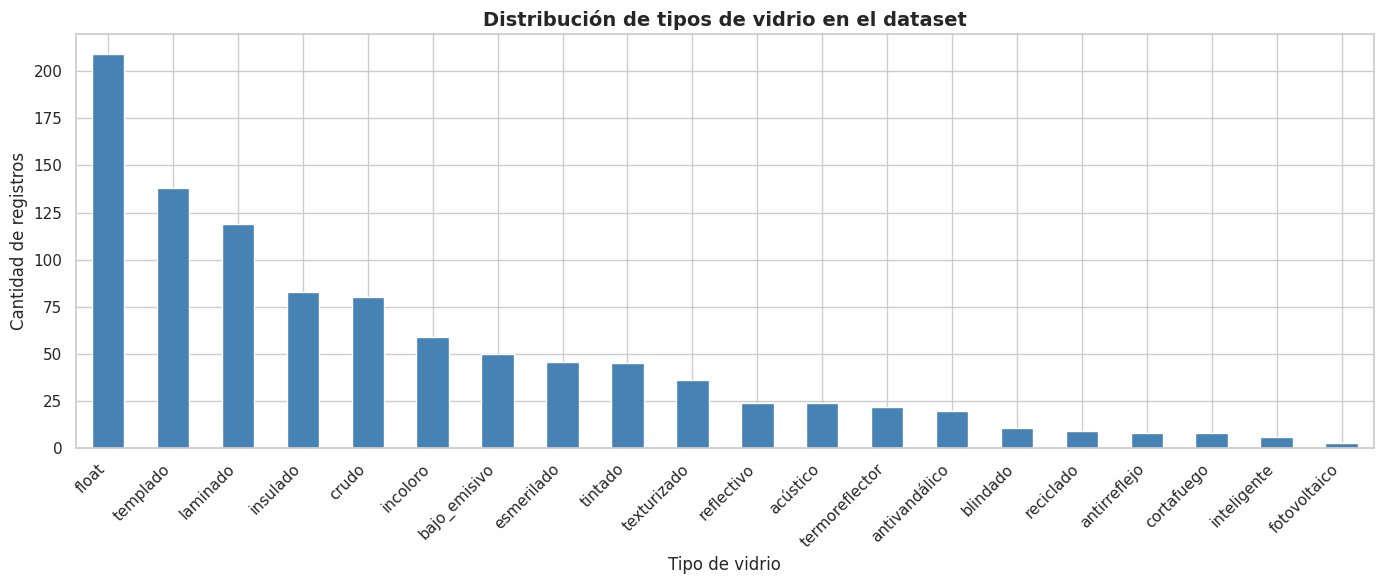


🏆 Tipo más frecuente: float (209 registros)
📉 Tipo menos frecuente: fotovoltaico (3 registros)


In [15]:
print("\n🪟 DISTRIBUCIÓN POR TIPO DE VIDRIO")
print("=" * 60)
tipos_count = df['tipo_vidrio'].value_counts()
print(tipos_count)

# Gráfico de distribución
plt.figure(figsize=(14, 6))
tipos_count.plot(kind='bar', color='steelblue')
plt.title('Distribución de tipos de vidrio en el dataset', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de vidrio', fontsize=12)
plt.ylabel('Cantidad de registros', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f"\n🏆 Tipo más frecuente: {tipos_count.idxmax()} ({tipos_count.max()} registros)")
print(f"📉 Tipo menos frecuente: {tipos_count.idxmin()} ({tipos_count.min()} registros)")


🌱 HUELLA DE CARBONO POR TIPO DE VIDRIO
                  mean    min      max  count
tipo_vidrio                                  
blindado        279.96  43.57   521.99     11
antivandálico   270.35   9.20   732.77     20
acústico        264.02  28.00  1063.61     24
insulado        253.06  16.62   754.68     83
bajo_emisivo    250.76  26.56   805.74     50
laminado        241.82  11.89   792.34    119
reflectivo      239.90  23.30   490.88     24
antirreflejo    237.03  31.39   533.62      8
texturizado     227.21  18.49   617.18     36
cortafuego      214.91  72.18   574.23      8
termoreflector  212.73  42.39   825.54     22
inteligente     211.99  53.80   334.96      6
templado        208.21  11.39   816.97    138
esmerilado      205.84  30.13   480.76     46
incoloro        202.47  20.68   632.37     59
tintado         188.89  15.45   807.08     45
float           181.46  10.97   566.94    209
fotovoltaico    180.24  40.69   429.58      3
crudo           166.20   9.95   673.29  

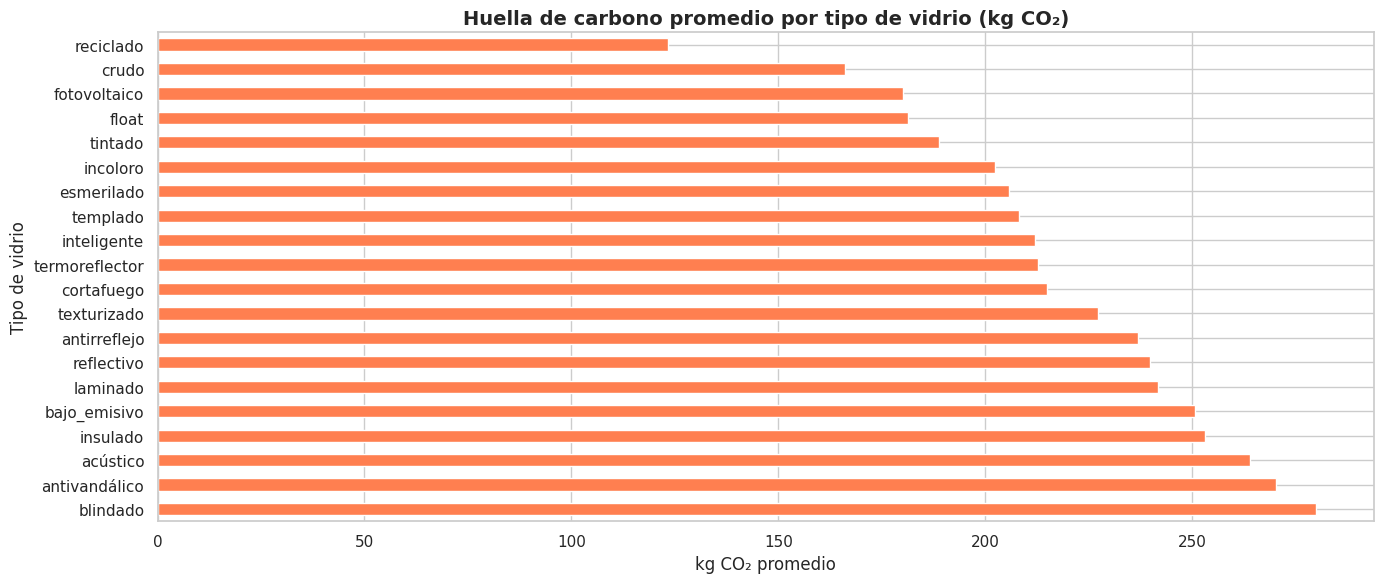


🏭 Tipo más contaminante: blindado (279.96 kg CO₂)
♻️ Tipo menos contaminante: reciclado (123.28 kg CO₂)


In [16]:
print("\n🌱 HUELLA DE CARBONO POR TIPO DE VIDRIO")
print("=" * 60)
co2_por_tipo = df.groupby('tipo_vidrio')['co2_kg'].agg(['mean', 'min', 'max', 'count'])
co2_por_tipo = co2_por_tipo.sort_values('mean', ascending=False)
print(co2_por_tipo.round(2))

# Gráfico comparativo
plt.figure(figsize=(14, 6))
co2_por_tipo['mean'].plot(kind='barh', color='coral')
plt.title('Huella de carbono promedio por tipo de vidrio (kg CO₂)', fontsize=14, fontweight='bold')
plt.xlabel('kg CO₂ promedio', fontsize=12)
plt.ylabel('Tipo de vidrio', fontsize=12)
plt.tight_layout()
plt.show()

print(f"\n🏭 Tipo más contaminante: {co2_por_tipo.index[0]} ({co2_por_tipo['mean'].iloc[0]:.2f} kg CO₂)")
print(f"♻️ Tipo menos contaminante: {co2_por_tipo.index[-1]} ({co2_por_tipo['mean'].iloc[-1]:.2f} kg CO₂)")


📈 ANÁLISIS DE CORRELACIONES


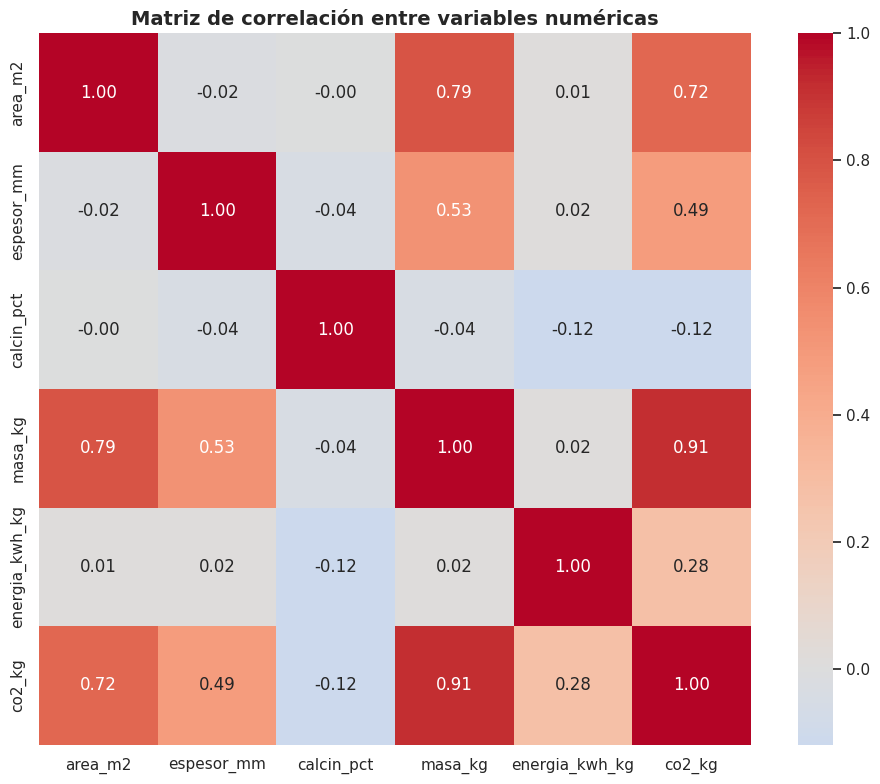


🔗 Correlaciones más fuertes con co2_kg:
co2_kg            1.000
masa_kg           0.913
area_m2           0.719
espesor_mm        0.486
energia_kwh_kg    0.276
calcin_pct       -0.118
Name: co2_kg, dtype: float64


In [17]:
print("\n📈 ANÁLISIS DE CORRELACIONES")
print("=" * 60)

# Matriz de correlación
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Matriz de correlación entre variables numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🔗 Correlaciones más fuertes con co2_kg:")
print(corr_matrix['co2_kg'].sort_values(ascending=False).round(3))

In [18]:
print("\n🔧 PREPARACIÓN DE DATOS PARA MODELADO")
print("=" * 60)

# Separar features y target
X = df.drop('co2_kg', axis=1)
y = df['co2_kg']

# Identificar columnas categóricas y numéricas
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"📋 Variables categóricas: {categorical_cols}")
print(f"🔢 Variables numéricas: {numerical_cols}")

# Dividir en train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df['tipo_vidrio']
)

print(f"\n✅ Conjunto de entrenamiento: {len(X_train)} registros ({len(X_train)/len(X)*100:.1f}%)")
print(f"✅ Conjunto de prueba: {len(X_test)} registros ({len(X_test)/len(X)*100:.1f}%)")


🔧 PREPARACIÓN DE DATOS PARA MODELADO
📋 Variables categóricas: ['tipo_vidrio', 'proceso']
🔢 Variables numéricas: ['area_m2', 'espesor_mm', 'calcin_pct', 'masa_kg', 'energia_kwh_kg']

✅ Conjunto de entrenamiento: 800 registros (80.0%)
✅ Conjunto de prueba: 200 registros (20.0%)


In [19]:
print("\n🔄 CONSTRUCCIÓN DEL PIPELINE DE PREPROCESAMIENTO")
print("=" * 60)

# Preprocesador para columnas categóricas (One-Hot Encoding)
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'  # Mantener columnas numéricas sin cambios
)

# Pipeline completo
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
])

print("✅ Pipeline creado:")
print("   1. OneHotEncoder para variables categóricas")
print("   2. RandomForestRegressor (200 árboles)")
print(f"\n📊 Features después del encoding: se expandirán de {len(X.columns)} a ~{len(X.columns) + df['tipo_vidrio'].nunique()}")


🔄 CONSTRUCCIÓN DEL PIPELINE DE PREPROCESAMIENTO
✅ Pipeline creado:
   1. OneHotEncoder para variables categóricas
   2. RandomForestRegressor (200 árboles)

📊 Features después del encoding: se expandirán de 7 a ~27


In [20]:
print("\n🎯 ENTRENAMIENTO DEL MODELO")
print("=" * 60)

# Entrenar
pipeline.fit(X_train, y_train)
print("✅ Modelo entrenado exitosamente")

# Predicciones
y_pred_train = pipeline.predict(X_train)
y_pred_test = pipeline.predict(X_test)

print(f"\n📊 Predicciones realizadas:")
print(f"   - Train: {len(y_pred_train)} predicciones")
print(f"   - Test: {len(y_pred_test)} predicciones")


🎯 ENTRENAMIENTO DEL MODELO
✅ Modelo entrenado exitosamente

📊 Predicciones realizadas:
   - Train: 800 predicciones
   - Test: 200 predicciones


In [21]:
print("\n📈 EVALUACIÓN DEL MODELO")
print("=" * 60)

# Métricas en train
mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

# Métricas en test
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print("\n🎯 MÉTRICAS DE RENDIMIENTO")
print("-" * 60)
print(f"{'Métrica':<20} {'Train':<15} {'Test':<15}")
print("-" * 60)
print(f"{'MAE (kg CO₂)':<20} {mae_train:<15.2f} {mae_test:<15.2f}")
print(f"{'RMSE (kg CO₂)':<20} {rmse_train:<15.2f} {rmse_test:<15.2f}")
print(f"{'R² Score':<20} {r2_train:<15.4f} {r2_test:<15.4f}")
print("-" * 60)

print("\n📊 INTERPRETACIÓN:")
print(f"   • MAE Test: El modelo se equivoca en promedio ±{mae_test:.2f} kg CO₂")
print(f"   • RMSE Test: Error cuadrático medio de {rmse_test:.2f} kg CO₂")
print(f"   • R² Test: El modelo explica el {r2_test*100:.1f}% de la variabilidad")

# Validación cruzada
print("\n🔄 VALIDACIÓN CRUZADA (5-fold)")
cv_scores = cross_val_score(pipeline, X, y, cv=5, scoring='r2', n_jobs=-1)
print(f"   • R² promedio CV: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"   • Rango: [{cv_scores.min():.4f}, {cv_scores.max():.4f}]")


📈 EVALUACIÓN DEL MODELO

🎯 MÉTRICAS DE RENDIMIENTO
------------------------------------------------------------
Métrica              Train           Test           
------------------------------------------------------------
MAE (kg CO₂)         7.81            20.69          
RMSE (kg CO₂)        12.94           33.49          
R² Score             0.9929          0.9461         
------------------------------------------------------------

📊 INTERPRETACIÓN:
   • MAE Test: El modelo se equivoca en promedio ±20.69 kg CO₂
   • RMSE Test: Error cuadrático medio de 33.49 kg CO₂
   • R² Test: El modelo explica el 94.6% de la variabilidad

🔄 VALIDACIÓN CRUZADA (5-fold)
   • R² promedio CV: 0.9456 ± 0.0123
   • Rango: [0.9322, 0.9668]



📊 VISUALIZACIÓN DE RESULTADOS


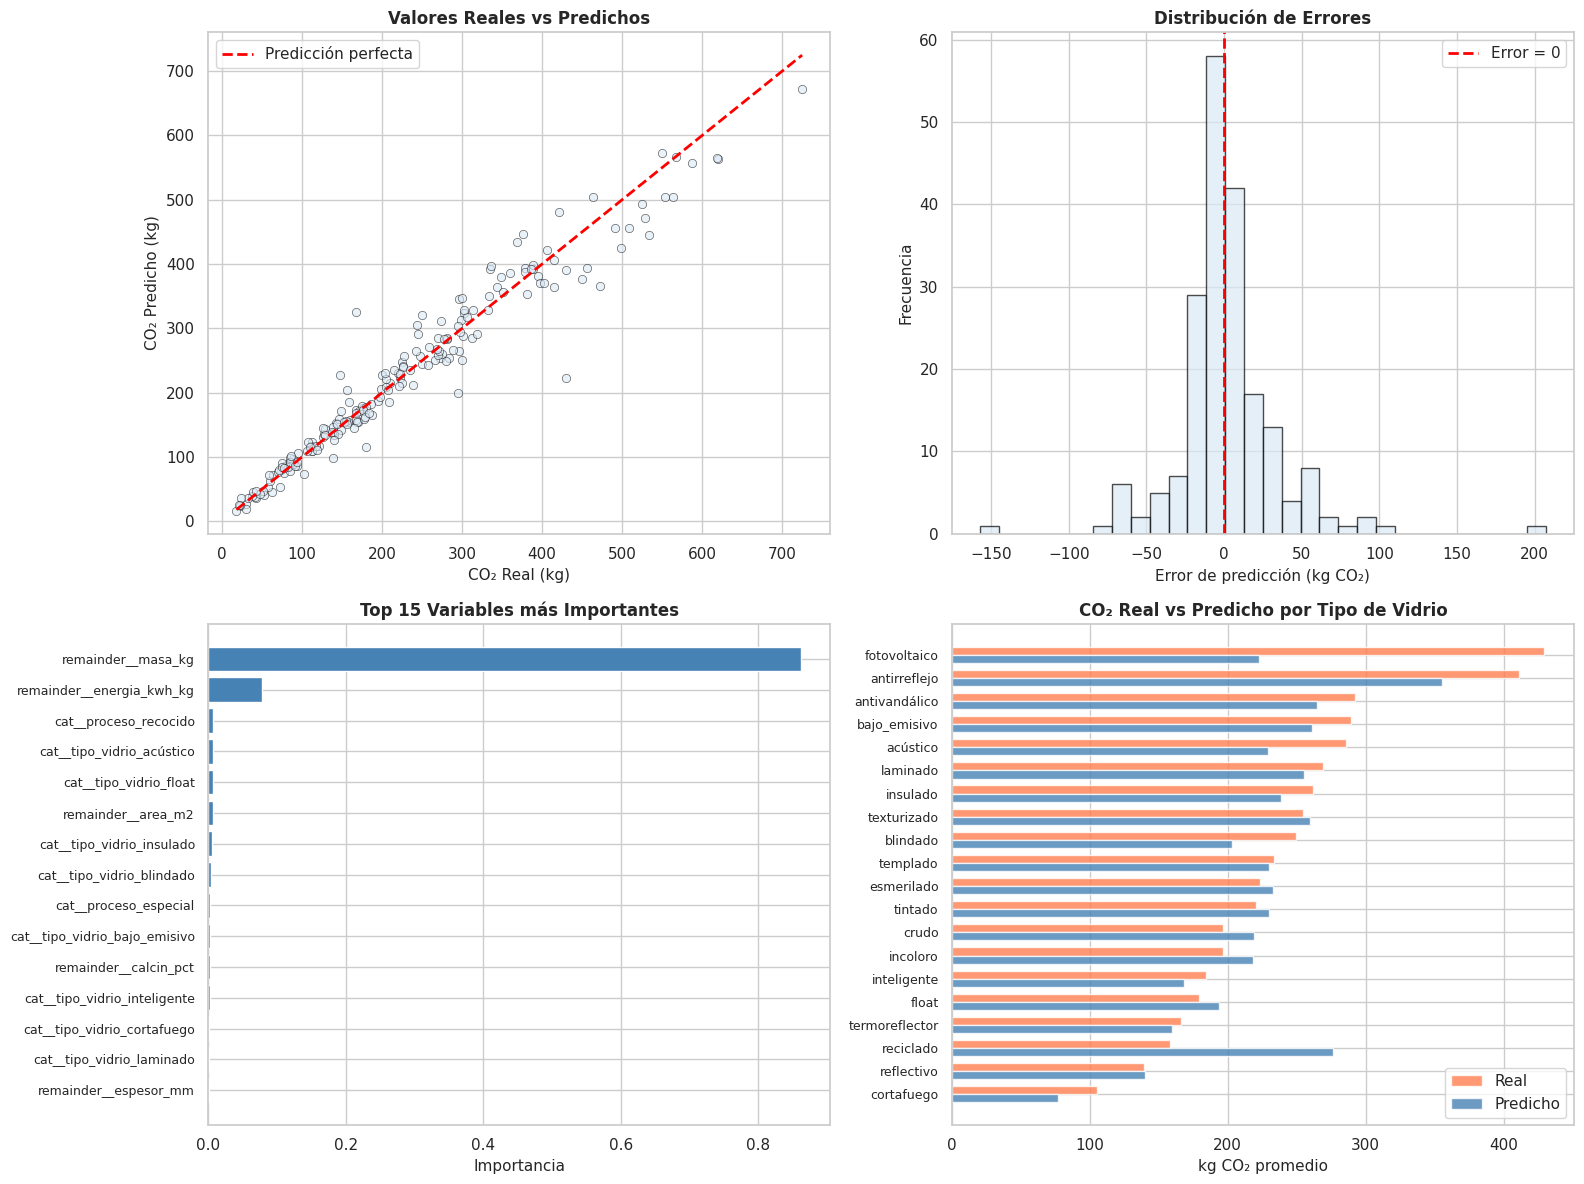

In [22]:
print("\n📊 VISUALIZACIÓN DE RESULTADOS")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Real vs Predicho
axes[0, 0].scatter(y_test, y_pred_test, alpha=0.6, edgecolors='k', linewidth=0.5)
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Predicción perfecta')
axes[0, 0].set_xlabel('CO₂ Real (kg)', fontsize=11)
axes[0, 0].set_ylabel('CO₂ Predicho (kg)', fontsize=11)
axes[0, 0].set_title('Valores Reales vs Predichos', fontsize=12, fontweight='bold')
axes[0, 0].legend()

# 2. Distribución de errores
errors = y_test - y_pred_test
axes[0, 1].hist(errors, bins=30, edgecolor='black', alpha=0.7)
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=2, label='Error = 0')
axes[0, 1].set_xlabel('Error de predicción (kg CO₂)', fontsize=11)
axes[0, 1].set_ylabel('Frecuencia', fontsize=11)
axes[0, 1].set_title('Distribución de Errores', fontsize=12, fontweight='bold')
axes[0, 1].legend()

# 3. Importancia de features
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = pipeline.named_steps['regressor'].feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

top_features = feature_importance_df.head(15)
axes[1, 0].barh(range(len(top_features)), top_features['importance'], color='steelblue')
axes[1, 0].set_yticks(range(len(top_features)))
axes[1, 0].set_yticklabels(top_features['feature'], fontsize=9)
axes[1, 0].set_xlabel('Importancia', fontsize=11)
axes[1, 0].set_title('Top 15 Variables más Importantes', fontsize=12, fontweight='bold')
axes[1, 0].invert_yaxis()

# 4. Predicciones por tipo de vidrio
test_df = X_test.copy()
test_df['co2_real'] = y_test.values
test_df['co2_pred'] = y_pred_test
co2_tipo_pred = test_df.groupby('tipo_vidrio')[['co2_real', 'co2_pred']].mean().sort_values('co2_real', ascending=False)

x_pos = np.arange(len(co2_tipo_pred))
width = 0.35
axes[1, 1].barh(x_pos - width/2, co2_tipo_pred['co2_real'], width, label='Real', color='coral', alpha=0.8)
axes[1, 1].barh(x_pos + width/2, co2_tipo_pred['co2_pred'], width, label='Predicho', color='steelblue', alpha=0.8)
axes[1, 1].set_yticks(x_pos)
axes[1, 1].set_yticklabels(co2_tipo_pred.index, fontsize=9)
axes[1, 1].set_xlabel('kg CO₂ promedio', fontsize=11)
axes[1, 1].set_title('CO₂ Real vs Predicho por Tipo de Vidrio', fontsize=12, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.show()

In [23]:
print("\n💾 GUARDADO DEL MODELO")
print("=" * 60)

# Guardar el pipeline completo
joblib.dump(pipeline, 'modelo_smartglass_co2.pkl')
print("✅ Modelo guardado como: modelo_smartglass_co2.pkl")

# Guardar métricas
metricas = {
    'mae_train': mae_train,
    'mae_test': mae_test,
    'rmse_train': rmse_train,
    'rmse_test': rmse_test,
    'r2_train': r2_train,
    'r2_test': r2_test,
    'cv_mean': cv_scores.mean(),
    'cv_std': cv_scores.std()
}

metricas_df = pd.DataFrame([metricas])
metricas_df.to_csv('metricas_modelo.csv', index=False)
print("✅ Métricas guardadas como: metricas_modelo.csv")

print("\n" + "=" * 60)
print("🎉 ANÁLISIS COMPLETADO EXITOSAMENTE")
print("=" * 60)
print(f"\n📊 Resumen final:")
print(f"   • Dataset: {len(df)} registros, {df['tipo_vidrio'].nunique()} tipos de vidrio")
print(f"   • Modelo: RandomForestRegressor (200 árboles)")
print(f"   • R² Test: {r2_test:.4f} ({r2_test*100:.1f}% de variabilidad explicada)")
print(f"   • MAE Test: ±{mae_test:.2f} kg CO₂")
print(f"   • Validación cruzada: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("\n✅ Listo para integrar en el aplicativo SmartGlass")


💾 GUARDADO DEL MODELO
✅ Modelo guardado como: modelo_smartglass_co2.pkl
✅ Métricas guardadas como: metricas_modelo.csv

🎉 ANÁLISIS COMPLETADO EXITOSAMENTE

📊 Resumen final:
   • Dataset: 1000 registros, 20 tipos de vidrio
   • Modelo: RandomForestRegressor (200 árboles)
   • R² Test: 0.9461 (94.6% de variabilidad explicada)
   • MAE Test: ±20.69 kg CO₂
   • Validación cruzada: 0.9456 ± 0.0123

✅ Listo para integrar en el aplicativo SmartGlass
